# IMDB Movie Reviews: Sentiment Analysis

## AI Foundations and Data Preparation

**Project:** IMDB Movie Reviews Sentiment Analysis
**Dataset:** IMDB Dataset of 50K Movie Reviews
**Tools:** Python, Pandas, NumPy, Matplotlib, NLTK
**Objective:** Clean and explore movie reviews, understand their sentiment distribution, and prepare the text for Natural Language Processing (NLP).

### Project Objectives
1. Load and inspect the dataset.
2. Clean the data while preserving the original dataset.
3. Explore positive and negative reviews.
4. Visualize important patterns.
5. Preprocess review text using NLP techniques.
6. Summarize findings and recommendations.

# Step 2 --- Import libraries

In [35]:
# Import the libraries needed for this project
import pandas as pd 
import numpy as np 
import html 
import matplotlib.pyplot as plt 
from pathlib import Path

#Display more columns when inspecting datasets
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## PART 2: Load the dataset

# Step 3 --- Find the original CSV file



**Note:** If it says False after runing the codes, the CSV file may be outside the project folder, or its filename maybe different.

In [86]:
# Define the project folders
PROJECT_DIR = Path.cwd().parent

RAW_DATA_PATH = PROJECT_DIR / "IMDB Dataset.csv"

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

CLEANED_DATA_PATH = PROCESSED_DIR / "imdb_cleaned.csv"

# Create the processed-data folder if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print("Project folder:", PROJECT_DIR) 
print("Raw dataset path:", RAW_DATA_PATH) 
print("Cleaned dataset path:", CLEANED_DATA_PATH)

Project folder: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data
Raw dataset path: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data\IMDB Dataset.csv
Cleaned dataset path: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data\data\processed\imdb_cleaned.csv


In [87]:
# Load the original dataset

# We are reading the raw data without modifying it.
raw_data = pd.read_csv(RAW_DATA_PATH)

# Create a working copy for analysis
imdb_cleaned = raw_data.copy()
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [70]:
# Display the first five rows 
imdb_cleaned.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [71]:
# Check the number of rows and columns 

print("Number of rows:", imdb_cleaned.shape[0])
print("Number of colunms:", imdb_cleaned.shape[1])

# Display the column names
print("Column name:", imdb_cleaned.columns.tolist())

Number of rows: 50000
Number of colunms: 2
Column name: ['review', 'sentiment']


In [72]:
# Identify the project folder
current_folder = Path.cwd()

if current_folder.name == "notebooks": 
    PROJECT_DIR = current_folder.parent 
else: 
    PROJECT_DIR = current_folder

# Define the expected location of the original dataset
RAW_DATA_PATH = PROJECT_DIR / "data" / "raw" / "IMDB Dataset.csv"

# If the file is not in the expected location, search the project folder
if not RAW_DATA_PATH.exists(): 
    matches = [ path for path in PROJECT_DIR.rglob("IMDB Dataset.csv") 
               if "processed" not in path.parts ]
if matches:
    RAW_DATA_PATH = matches[0]

print("Project folder:", PROJECT_DIR) 
print("Dataset location:", RAW_DATA_PATH) 
print("Dataset found:", RAW_DATA_PATH.exists())

Project folder: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data\IMDB-SENTIMENT-ANALYSIS-NOTEBOOK
Dataset location: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data\IMDB-SENTIMENT-ANALYSIS-NOTEBOOK\data\raw\IMDB Dataset.csv
Dataset found: False


## Step 4 --- Load the raw dataset
 
 Once Srep 3 report True, then free to continue

In [88]:
# Load the original dataset without modifying it

raw_data = pd.read_csv(RAW_DATA_PATH)

# Create a separarte working copy for our analysis 

df = raw_data.copy()

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 50000
Number of columns: 2


## Step 5 --- Inspect the dataset

**The result:** These checks help understand the data before cleaning it.

In [89]:
# Display the first five records
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [90]:
# Inspect the dataset structure

print("Column names:", df.columns.tolist())

print("Dataset Informaion:", df.info())


Column names: ['review', 'sentiment']
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
Dataset Informaion: None


In [91]:
# Check missing values
print("Missing values in each column:", df.isnull().sum())

# Check duplicaten rows
print("Number of duplicate rows:", df.duplicated().sum())


Missing values in each column: review       0
sentiment    0
dtype: int64
Number of duplicate rows: 418


## PART 3: Clean the dataset

## Step 6 — Clean the data safely

## Data Cleaning and Preparation
The raw dataset is preserved separately. Cleaning operations are performed on a copy so that the original data remains unchnaged.

In [92]:
# Create a fresh copy of the original data
imdb_clean = raw_data.copy()

# Standardize column names
imdb_clean.columns = imdb_clean.columns.str.strip().str.lower()

# Check that the required columns exist
required_columns = {"review","sentiment"}

if not required_columns.issubset(imdb_clean.columns):
    raise ValueError(
        f"Expected columns {required_columns} "
        f"but found {set(imdb_clean.columns)}"
    )

# Remove records with missing reviews or sentiment labels
imdb_clean = imdb_clean.dropna(subset=["review","sentiment"]).copy()

# Remove leading and trailing spaces

imdb_clean["review"] = imdb_clean["review"].astype(str).str.strip() 
imdb_clean["sentiment"] = ( imdb_clean["sentiment"].astype(str).str.strip().str.lower() )

# Remove empty reviews
imdb_clean = imdb_clean[imdb_clean["review"] != ""].copy()

# Keep only valid sentiment labels
imdb_clean = imdb_clean[ imdb_clean["sentiment"].isin(["positive", "negative"]) ].copy()

# Remove duplicate records
imdb_clean = imdb_clean.drop_duplicates()

# Reset the row index
imdb_clean = imdb_clean.reset_index(drop=True)
print("Cleaning completed!") 
print("Original rows:", len(raw_data)) 
print("Cleaned rows:", len(imdb_clean)) 
print("Rows removed:", len(raw_data) - len(imdb_clean))

Cleaning completed!
Original rows: 50000
Cleaned rows: 49582
Rows removed: 418


**What this code does**

- Preserves the original dataset.

- Removes records with missing review text or sentiment.

- Removes unnecessary spaces.

- Standardizes sentiment labels.

- Removes empty reviews and duplicate records.

- Keeps only positive and negative sentiment labels.

**Note:** The number of cleaned rows depends on the actual contents of your original CSV.

**Step 7 — Save the cleaned dataset**


In [93]:
#Create the processed-data folder

PROCESSED_DIR = PROJECT_DIR / "data" / "processed" 
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

#Save the cleaned data as a separate file

CLEANED_DATA_PATH = PROCESSED_DIR / "imdb_cleaned.csv"

imdb_clean.to_csv(CLEANED_DATA_PATH, index=False)

print("Cleaned dataset saved successfully!") 
print("Saved to:", CLEANED_DATA_PATH)

Cleaned dataset saved successfully!
Saved to: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data\data\processed\imdb_cleaned.csv


**Your project now has two separate datasets:**

**- Raw dataset:** The original data.
**- Cleaned dataset:** The processed copy.

Never save the cleaned data over your original CSV.

## PART 4: Exploratory Data Analysis (EDA)

EDA helps us understand the data before attempting to build a machine-learning model.

## Step 8 --- Summary Statistcis

## Exploratory Data Analysis
Exploratory Data Analysis is used to understand the structure, distribution, and characteristics of the dataset.

In [94]:
# Display the first five records of the cleaned dataset

imdb_clean.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [95]:
# Examine the dimensions and data types

print("Dataset dimensions:", imdb_clean.shape)

print("\nData types:",imdb_clean.dtypes) 

print("\nMissing values:",imdb_clean.isnull().sum()) 

print("\nDuplicate rows:",imdb_clean.duplicated().sum()) 


Dataset dimensions: (49582, 2)

Data types: review       str
sentiment    str
dtype: object

Missing values: review       0
sentiment    0
dtype: int64

Duplicate rows: 0


## Step 9: Analyze Sentiment Distribution

In [96]:
# Count the positive and negative reviews

sentiment_counts = imdb_clean["sentiment"].value_counts()

print("Sentiment counts:") 
print(sentiment_counts)

print("Sentiment percentages:", (imdb_clean["sentiment"].value_counts(normalize=True) * 100) .round(2) )

Sentiment counts:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64
Sentiment percentages: sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64


Now create a visualization:

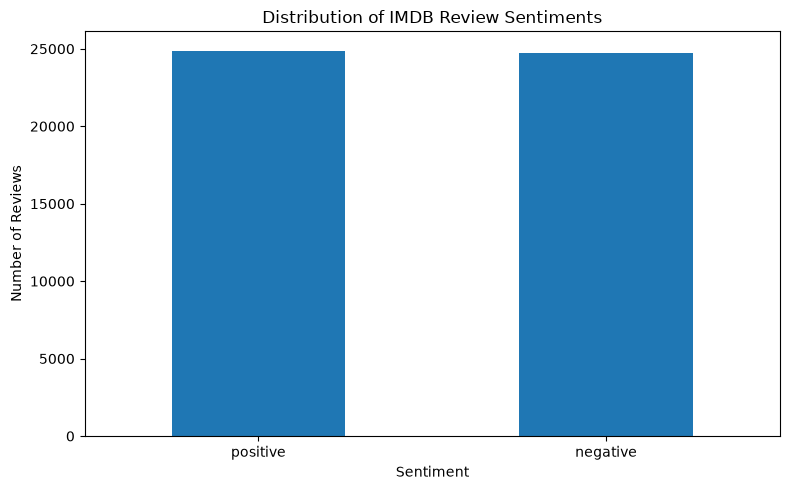

In [97]:
#Visualize the distribution of sentiment labels

sentiment_counts = imdb_clean["sentiment"].value_counts()

plt.figure(figsize=(8, 5))

sentiment_counts.plot(kind="bar")
plt.title("Distribution of IMDB Review Sentiments") 
plt.xlabel("Sentiment") 
plt.ylabel("Number of Reviews") 
plt.xticks(rotation=0)
plt.tight_layout() 
plt.savefig("Distribution of IMDB Review Sentiments.png")

**What are we investigation?**

Whether the dataset contains more positive reviews or negative reviews.

## Step 10 --- Analysis review lengths 

First, create a new column containing the character length of each review.

In [98]:
# Calculate the length of each review in characters
imdb_clean["review_length"] = imdb_clean["review"].str.len()

# Display summary statistics for review length
imdb_clean["review_length"].describe()

count    49582.000000
mean      1310.566657
std        990.760997
min         32.000000
25%        699.000000
50%        971.000000
75%       1592.000000
max      13704.000000
Name: review_length, dtype: float64

Next, compare the average lengths of positive and negatives reviews

In [99]:
# Calculate the average review length for each sentiment

average_length = imdb_clean.groupby("sentiment")["review_length"].mean()

print("Average review length by sentiment:") 
print(average_length.round(2))

Average review length by sentiment:
sentiment
negative    1294.74
positive    1326.28
Name: review_length, dtype: float64


Now visualize the results:

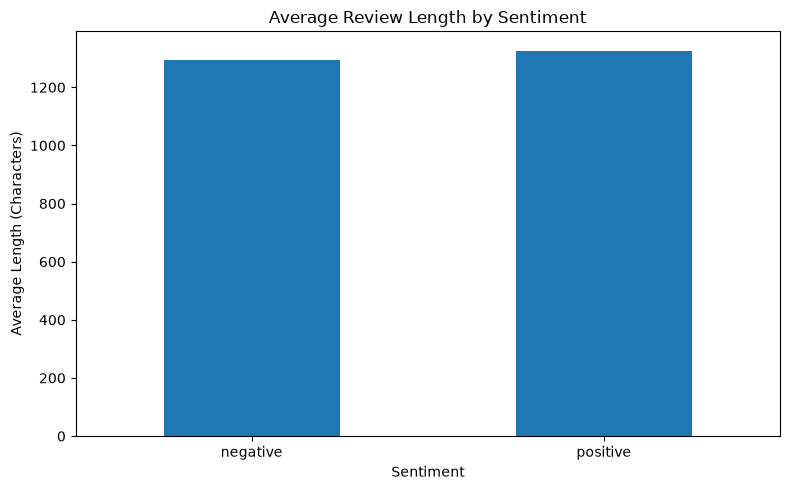

In [100]:
# Compare average review lengths

plt.figure(figsize=(8, 5))

average_length.plot(kind="bar")

plt.title("Average Review Length by Sentiment") 
plt.xlabel("Sentiment") 
plt.ylabel("Average Length (Characters)") 
plt.xticks(rotation=0)
plt.tight_layout() 
plt.savefig("Average Review Length by Sentiment.png")

Finally, examine the distribution of reviews lengths:

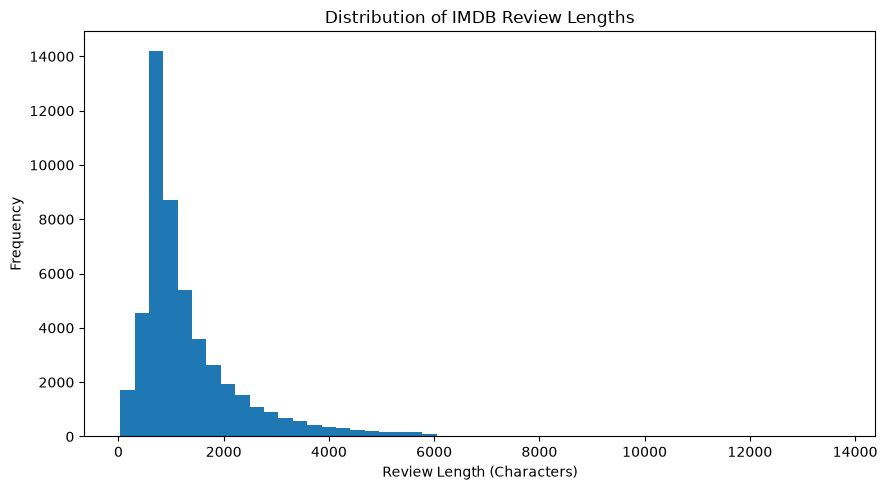

In [101]:
# Display the distribution of review lengths

plt.figure(figsize=(9, 5))

plt.hist( 
    imdb_clean["review_length"], 
    bins=50 )
plt.title("Distribution of IMDB Review Lengths") 
plt.xlabel("Review Length (Characters)") 
plt.ylabel("Frequency")
plt.tight_layout() 
plt.savefig("Distribution of IMDB Review Lengths.png")

This three visualizations givs a usefull starting point for understanding the reviews.

## PART 5: Natural Language Processing (NLP)

NLP allows computers to process and analyze human language.

For this project, we will lowercase text, remove HTML tags, tokenize reviews, and remove common English stopwords while preserving important negation words such as not and never.

## Step 11 --- Install and prepare NLTK

## Natural Language Processing

Natural Language Processing (NLP) involves preparing and analyzing human language so that computers can work with text data.

In [102]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

# Import NLTK tools
import nltk

from nltk.corpus import stopwords 
from nltk.tokenize import TreebankWordTokenizer

# Download the English stopword list if necessary

nltk.download("stopwords", quiet=True)

# Create a tokenizer
tokenizer = TreebankWordTokenizer()

print("NLP tools are ready!")

NLP tools are ready!


[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


## Step 12 ---- Define the text preprocessing function

In [103]:
# Define words that should not be removed

import re
import html
import pandas as pd  
import nltk
import re  
import ssl
ssl._create_default_https_contex = ssl._create_unverified_context

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# These words can be important for sentiment analysis.

negation_words = {"no", "nor", "not", "never"}

# Load English stopwords

stop_words = set(stopwords.words("english"))

# Preserve negation words
stop_words = stop_words - negation_words

def preprocess_review(text): """ Clean and tokenize a movie review.
Operations:
1. Convert HTML entities into normal characters.
2. Remove HTML tags.
3. Convert text to lowercase.
4. Tokenize the text.
5. Remove stopwords and non-alphabetic tokens.
"""

def preprocess_review(text):
    # Concert text to lowercase
    text = text.lower()
    # Remove HTML tags
    text = re.sub(r"<.*?>", "",text)
    # Tokenize the review
    tokens = word_tokenize(text)
    # Keep alphabetic words remove stopwords
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]
    # Return the processed tokens
    return tokens 

print("Preprocessing function created successfully!")

Preprocessing function created successfully!


## Step 13 --- Test the preprocessing function

**Before processing thousands of reviews, test it on one review.**

**The Output:** You shoud see the original text followed by a list of cleaning tokens.

In [104]:
# Select one example review

sample_review = imdb_clean["review"].iloc[0]

print("Original review:",sample_review[:500]) 
print("Processed tokens:",preprocess_review(sample_review)[:50]) 

Original review: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ
Processed tokens: ['one', 'reviewers', 'mentioned', 'watching', 'oz', 'episode', 'hooked', 'right', 'exactly', 'happened', 'first', 'thing', 'struck', 'oz', 'brutality', 'unflinching', 'scenes', 'violence', 'set', 'right', 'word', 'go', 'trust', 'not', 'show', 'faint', 'hearted', 'timid', 'show', 'pulls', 'no', 'punches', 'regards', 'drugs', 'sex', 'violence', 'hardcore', 'classic', 'use', 'called', 'oz', 'nickname', 'given', 'oswald', 'maximum', 'security', 'state', 'penitenta

## Step 14 --- Process the reviews 

In [105]:
# Create a separate dataset for NLP processing

imdb_nlp = imdb_clean[["review", "sentiment"]].copy()

# Tokenize and clean each review

imdb_nlp["tokens"] = imdb_nlp["review"].apply(preprocess_review)

# Convert the token lists into strings for convenient storage

imdb_nlp["processed_review"] = imdb_nlp["tokens"].apply( 
    lambda tokens: " ".join(tokens) )

print("NLP preprocessing completed!")

imdb_nlp.head()

NLP preprocessing completed!


,review,sentiment,tokens,processed_review
0,One of the other reviewers has mentioned that ...,positive,"[one, reviewers, mentioned, watching, oz, epis...",one reviewers mentioned watching oz episode ho...
1,A wonderful little production. <br /><br />The...,positive,"[wonderful, little, production, filming, techn...",wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,positive,"[thought, wonderful, way, spend, time, hot, su...",thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,"[basically, family, little, boy, jake, thinks,...",basically family little boy jake thinks zombie...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,"[petter, mattei, love, time, money, visually, ...",petter mattei love time money visually stunnin...


## Step 14 
This creates two additional columns:
1. **tokens:** The individual cleaned words.
2. **processed_review:** The cleaned words joined into a single text string.

## Step 15 --- Save the NLP dataset

In [106]:
#Save the NLP-preprocessed dataset separately

NLP_DATA_PATH = PROCESSED_DIR / "imdb_nlp_processed.csv"

# Save a CSV-friendly version of the data

imdb_nlp[ ["review", "sentiment", "processed_review"] 
].to_csv(NLP_DATA_PATH, index=False)

print("NLP dataset saved successfully!") 
print("Saved to:", NLP_DATA_PATH)

NLP dataset saved successfully!
Saved to: c:\Users\USER\OneDrive\Desktop\General's files\APPLIED MATHEMATICS AND STATISTIC BOOKS\Compuational Skills\data\data\processed\imdb_nlp_processed.csv


## Step 15
**Your processed folder should now contains:**
data/
├── raw/
│   └── IMDB Dataset.csv
│
└── processed/
    ├── imdb_cleaned.csv
    └── imdb_nlp_processed.csv

The first processed file contains the cleaned reviews. The second contains the text after NLP preprocessing.

### PART 6: Final finding and concusions

## Step 16 -- Generate a result summary

In [107]:
# Calculate key project statistics

total_reviews = len(imdb_clean)

sentiment_percentages = ( 
    imdb_clean["sentiment"]
     .value_counts(normalize=True)
     .mul(100)
     .round(2) )

average_lengths = ( 
    imdb_clean.groupby("sentiment")["review_length"]
     .mean()
     .round(2) )

print("IMDB SENTIMENT ANALYSIS SUMMARY") 
print("=" * 40)

print(f"Total cleaned reviews: {total_reviews:,}")

print("Sentiment percentages:",sentiment_percentages)

print("Average review length by sentiment:",average_lengths)

print("Missing values:",imdb_clean[["review", "sentiment"]].isnull().sum())

print("NLP preprocessing completed:", "tokens" in imdb_nlp.columns)

IMDB SENTIMENT ANALYSIS SUMMARY
Total cleaned reviews: 49,582
Sentiment percentages: sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64
Average review length by sentiment: sentiment
negative    1294.74
positive    1326.28
Name: review_length, dtype: float64
Missing values: review       0
sentiment    0
dtype: int64
NLP preprocessing completed: True


## Step 16 
**This cell calculate the result from your actual dataset rather than relying on assumed numbers.**

## Step 17 --- Write the conclusion

## Conclusion
This project involved cleaning, exploring, and preprocessing the IMDB movie review dataset.

The data cleaning stage addressed missing values, duplicate records, inconsistent sentiment labels, and unnecessary spaces while preserving the original dataset.

Exploratory Data Analysis was used to examine sentiment distribution and review lengths. Visualizations helped make the patterns easier to understand.

Natural Language Processing techniques were then applied to prepare the reviews for further text analysis. These techniques included converting text to lowercase, removing HTML tags, tokenization, and stopword removal while preserving important negation words.

### Limitations

The analysis focuses on data preparation and exploratory analysis. It does not yet establish how accurately a machine-learning model can classify sentiment.

### Future Work

Future improvements could include:
- Building a machine-learning sentiment classifier.
- Comparing models such as Logistic Regression and Naive Bayes.
- Evaluating model performance using accuracy, precision, recall, and F1-score.
- Investigating errors in sentiment predictions.

## PART 7: Save and organize your project
 **Your project should be organizes approximately like this:**


 IMDB-Sentiment-Analysis/
│
├── data/
│   ├── raw/
│   │   └── IMDB Dataset.csv
│   │
│   └── processed/
│       ├── imdb_cleaned.csv
│       └── imdb_nlp_processed.csv
│
├── notebooks/
│   └── imdb_eda.ipynb
│
├── scripts/
│   ├── data_preprocessing.py
│   ├── imdb_eda.py
│   └── text_preprocessing.py
│
├── reports/
│   └── insights_summary.md
│
└── README.md

**You can keep your existing Python scripts alongside the notebook.**